In [1]:
%% MIT 18.03 Lecture 3: First-Order LTI Systems & Signals Perspective
% Description: Simulates first-order dynamic systems (RC Circuit / Standard Form).
%              Decomposes total response into Zero-Input Response (ZIR) and
%              Zero-State Response (ZSR). Computes time and frequency domain metrics.
%
% % MBD Concept Mapping: Demonstrates the fundamental LTI block: Input -> System -> Output.
%                      Maps physical parameters (R, C) to system pole s = -1/(R*C),
%                      time constant tau = RC, and cutoff frequency omega_c = 1/tau.


clear; clc; close all;


%% 1. Physical System Parameter Definitions (Series RC Circuit)
R = 1000;         % Resistance: 1 kOhm (1000 Ohms)
C = 1e-6;         % Capacitance: 1 uF (1e-6 Farads)
tau = R * C;      % System Time Constant tau = RC (seconds)
omega_c = 1 / tau;% Cutoff frequency (rad/s)


fprintf('=== First-Order LTI System Characteristics ===\n');

=== First-Order LTI System Characteristics ===

In [2]:
fprintf('Resistance (R)      : %.2f Ohm\n', R);

Resistance (R)      : 1000.00 Ohm

In [3]:
fprintf('Capacitance (C)     : %.2e F\n', C);

Capacitance (C)     : 1.00e-06 F

In [4]:
fprintf('Time Constant (tau) : %.4f s\n', tau);

Time Constant (tau) : 0.0010 s

In [5]:
fprintf('System Pole (p)     : %.4f rad/s\n', -1/tau);

System Pole (p)     : -1000.0000 rad/s

In [6]:
fprintf('Cutoff Frequency    : %.4f rad/s (%.2f Hz)\n', omega_c, omega_c / (2*pi));

Cutoff Frequency    : 1000.0000 rad/s (159.15 Hz)

In [7]:
fprintf('==============================================\n\n');


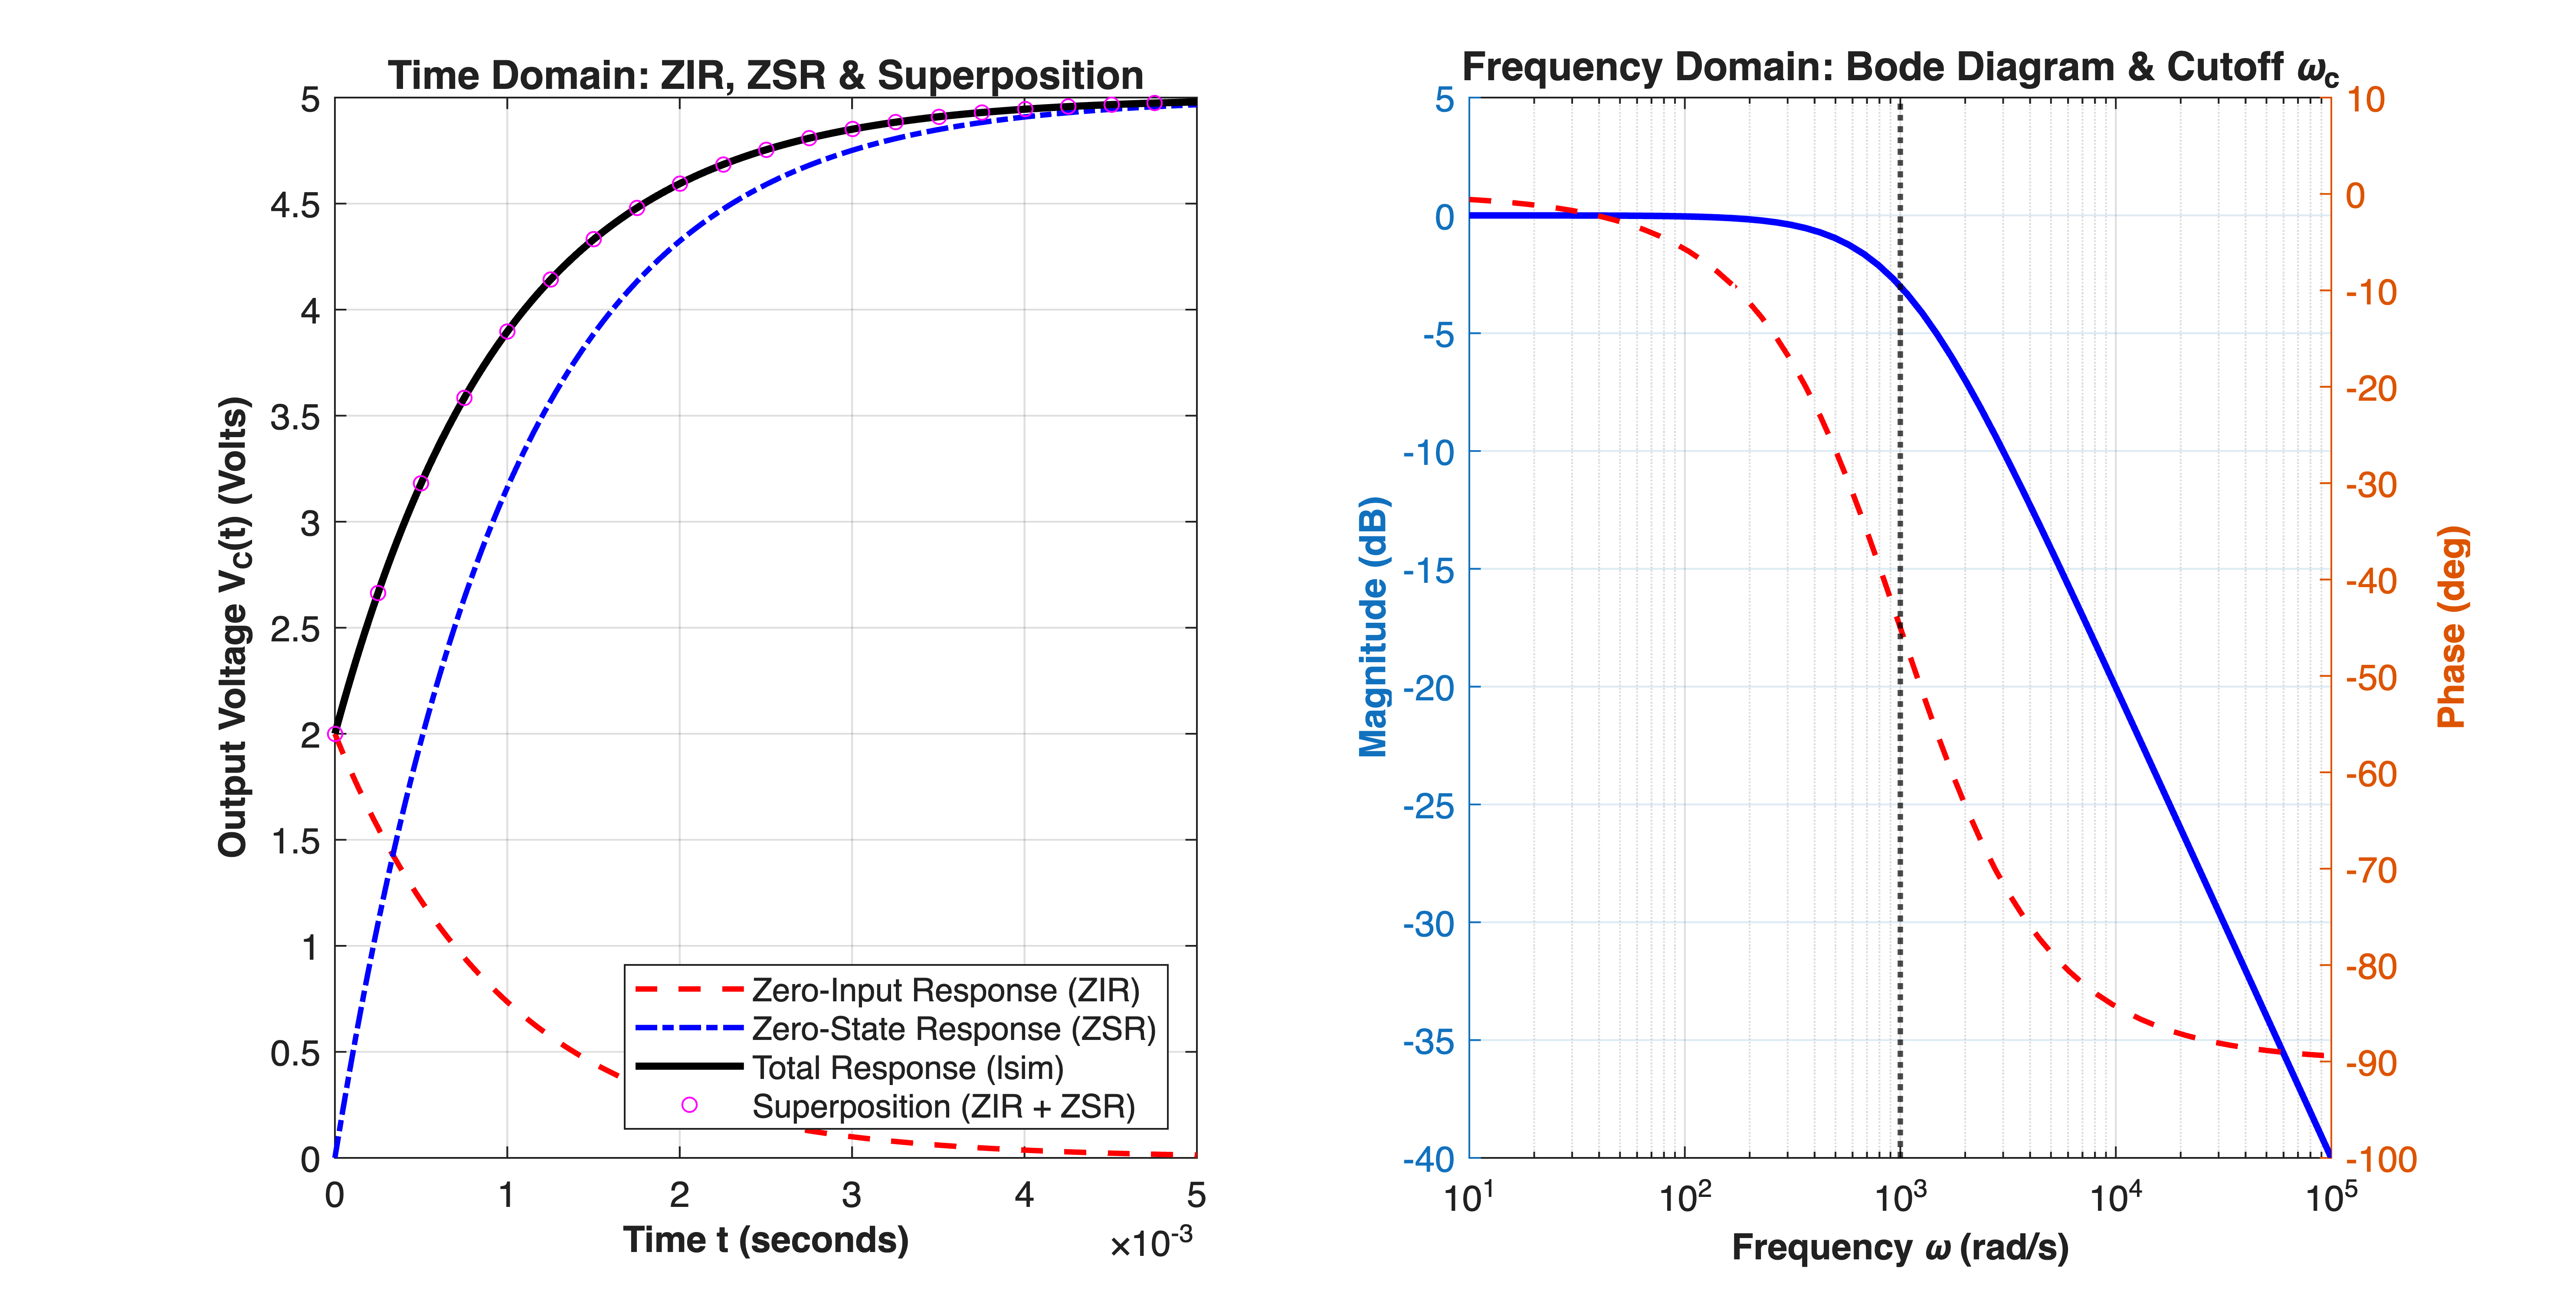

In [8]:


%% 2. LTI Model Construction (Capacitor Voltage as Output: tau*dy/dt + y = u)
% Transfer Function: G(s) = 1 / (tau*s + 1)
num = 1;
den = [tau, 1];
sys_tf = tf(num, den);


% State-Space Representation: dx/dt = A*x + B*u, y = C_mat*x + D_mat*u
A = -1 / tau;
B = 1 / tau;
C_mat = 1;
D_mat = 0;
sys_ss = ss(A, B, C_mat, D_mat);


%% 3. Time-Domain Response Decomposition: ZIR + ZSR = Total Response
t_sim = linspace(0, 5 * tau, 1000); % Simulate for 5 time constants
u_step = 5.0 * ones(size(t_sim));   % 5V Step Input Signal
y0 = 2.0;                           % Initial state condition: V_c(0) = 2.0 V


% Compute Zero-Input Response (ZIR): Input = 0, State = y0
% Analytical ZIR: y_zir(t) = y0 * exp(-t / tau)
y_zir = initial(sys_ss, y0, t_sim);


% Compute Zero-State Response (ZSR): Input = u_step, State = 0
y_zsr = lsim(sys_ss, u_step, t_sim, 0);


% Compute Total Response: Input = u_step, State = y0
y_total_sim = lsim(sys_ss, u_step, t_sim, y0);
y_superposition = y_zir + y_zsr;


%% 4. Figure 1: Time-Domain Response & Superposition Verification
figure('Color', [1 1 1], 'Position', [100, 100, 950, 480]);


subplot(1, 2, 1);
plot(t_sim, y_zir, 'r--', 'LineWidth', 1.5, 'DisplayName', 'Zero-Input Response (ZIR)');
hold on; grid on; box on;
plot(t_sim, y_zsr, 'b-.', 'LineWidth', 1.5, 'DisplayName', 'Zero-State Response (ZSR)');
plot(t_sim, y_total_sim, 'k-', 'LineWidth', 2.0, 'DisplayName', 'Total Response (lsim)');
plot(t_sim, y_superposition, 'mo', 'MarkerIndices', 1:50:length(t_sim), ...
    'MarkerSize', 4, 'DisplayName', 'Superposition (ZIR + ZSR)');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Output Voltage V_C(t) (Volts)', 'FontSize', 10, 'FontWeight', 'bold');
title('Time Domain: ZIR, ZSR & Superposition', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'southeast', 'FontSize', 9);
xlim([0, 5 * tau]);


%% 5. Figure 2: Frequency-Domain Analysis (Bode Plot of First-Order Filter)
subplot(1, 2, 2);
[mag, phase, w_out] = bode(sys_tf, {omega_c * 0.01, omega_c * 100});
mag_dB = 20 * log10(squeeze(mag));
phase_deg = squeeze(phase);


yyaxis left;
semilogx(w_out, mag_dB, 'b-', 'LineWidth', 1.8);
ylabel('Magnitude (dB)', 'FontSize', 10, 'FontWeight', 'bold');
ylim([-40, 5]);


yyaxis right;
semilogx(w_out, phase_deg, 'r--', 'LineWidth', 1.5);
ylabel('Phase (deg)', 'FontSize', 10, 'FontWeight', 'bold');
ylim([-100, 10]);


grid on; box on;
xlabel('Frequency \omega (rad/s)', 'FontSize', 10, 'FontWeight', 'bold');
title('Frequency Domain: Bode Diagram & Cutoff \omega_c', 'FontSize', 11, 'FontWeight', 'bold');
xline(omega_c, 'k:', 'LineWidth', 1.5, 'DisplayName', '\omega_c = 1/\tau');